# Assignment 7 — Style Transfer: NST vs. AdaIN vs. Stable Diffusion

Transfer the artistic style of **two Bangladeshi masters — Zainul (Jainul) Abedin** and
**S. M. Sultan** — onto our own content photographs, using three techniques, and compare them:

1. **Neural Style Transfer (NST)** — classical VGG-19 + Gram matrices, optimised per image.
2. **AdaIN** — arbitrary style transfer by aligning feature mean/std (feed-forward).
3. **Stable Diffusion** — diffusion-based style transfer (img2img + IP-Adapter on the painting).

Each of the **10 content images** is stylised with **both** an Abedin painting **and** a Sultan
painting (paintings chosen to suit each photo), giving **20 stylizations per method (60 images
total)**. The same content images and the same paintings are reused across all three methods for a
fair comparison.

| Report section | Where produced |
|---|---|
| Dataset description | §2 |
| NST implementation + results | §3 |
| AdaIN implementation + results | §4 |
| Stable Diffusion implementation + results | §5 |
| Comparative analysis (quant + qual) | §6 |
| Discussion (evolution + 10 questions) | §7 |

## 0. Environment

In [1]:
%pip install -q "diffusers>=0.27" "transformers>=4.38" accelerate safetensors "torchmetrics[image]" matplotlib pandas pillow tqdm huggingface_hub opencv-python-headless

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Imports and configuration

In [2]:
import os, gc, json, time, math, random
from pathlib import Path
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torchvision.models import vgg19, VGG19_Weights

torch.backends.cuda.matmul.allow_tf32 = True

@dataclass
class CFG:
    content_dir: str = "content_images"
    style_root:  str = "style_images"          # contains subfolders 'jaynul abedin' and 'sm sultan'
    img_size:    int = 512
    nst_steps: int = 300
    nst_lr: float = 0.02
    nst_content_weight: float = 1.0
    nst_style_weight: float = 1e6
    sd_model_id: str = "stable-diffusion-v1-5/stable-diffusion-v1-5"
    sd_strength: float = 0.7            # ControlNet locks structure, so strength mainly restyles
    sd_guidance: float = 7.5
    sd_steps: int = 30
    sd_controlnet_scale: float = 0.9    # Canny ControlNet: preserves the content object/structure
    sd_ip_scale: float = 0.5            # IP-Adapter style strength (modest so painting subjects
                                        # are not copied in, only the painterly style)
    use_ip_adapter: bool = True
    seed: int = 42
    quick_mode: bool = True

CFG = CFG()
if CFG.quick_mode: CFG.nst_steps = 150

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(CFG.seed)

device = "cuda" if torch.cuda.is_available() else "cpu"
use_cuda = device == "cuda"
weight_dtype = torch.float16 if use_cuda else torch.float32

OUT = Path("outputs")
FIG, RES = OUT/"figures", OUT/"results"
DIRS = {m: OUT/m for m in ["nst", "adain", "sd"]}
for d in [FIG, RES, *DIRS.values()]: d.mkdir(parents=True, exist_ok=True)
print(f"device={device}  gpu={torch.cuda.get_device_name(0) if use_cuda else 'cpu'}")
print("config:", json.dumps(asdict(CFG), indent=2))

device=cuda  gpu=NVIDIA GeForce RTX 5070 Ti
config: {
  "content_dir": "content_images",
  "style_root": "style_images",
  "img_size": 512,
  "nst_steps": 150,
  "nst_lr": 0.02,
  "nst_content_weight": 1.0,
  "nst_style_weight": 1000000.0,
  "sd_model_id": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "sd_strength": 0.7,
  "sd_guidance": 7.5,
  "sd_steps": 30,
  "sd_controlnet_scale": 0.9,
  "sd_ip_scale": 0.5,
  "use_ip_adapter": true,
  "seed": 42,
  "quick_mode": true
}


## 2. Dataset preparation (Task 1)

- **Content images:** our 10 smartphone/camera photographs (`content_images/`).
- **Style images:** paintings by **Zainul Abedin** (`style_images/jaynul abedin/`) and **S. M. Sultan**
  (`style_images/sm sultan/`).

**Chosen pairings.** For every content photo we pick one Abedin painting *and* one Sultan painting
whose palette / subject / mood suits that photo (analysed by hand), so the transfer is coherent.
This yields **20 (content, style) pairs** — 10 per artist. Everything is centre-cropped to a square
`img_size` so all methods and metrics use identical inputs.

10 content images x 2 artists = 20 stylization tasks


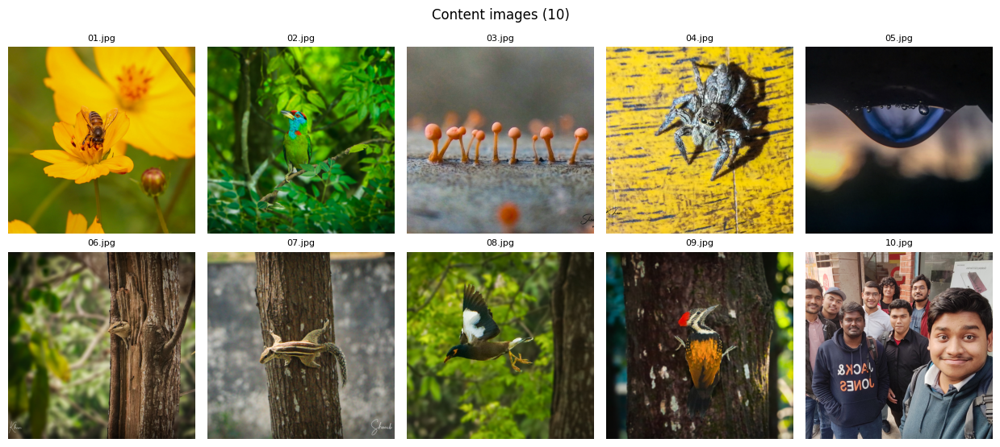

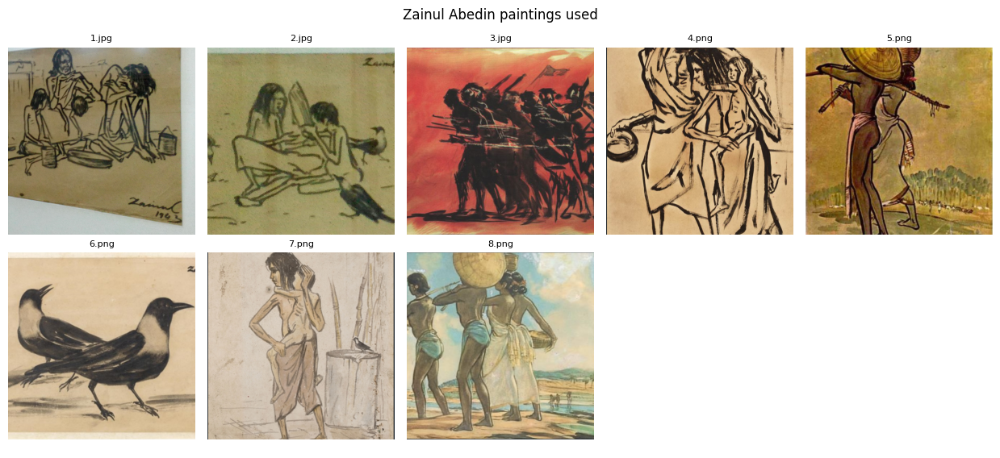

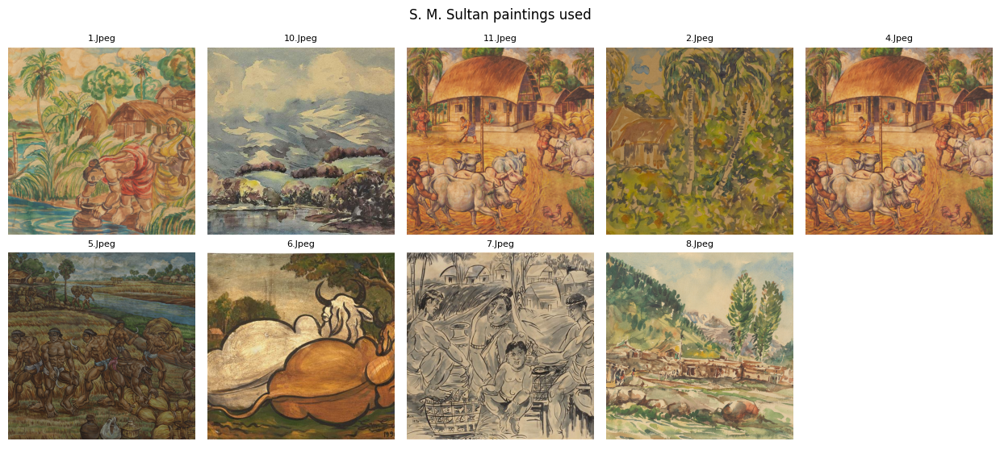

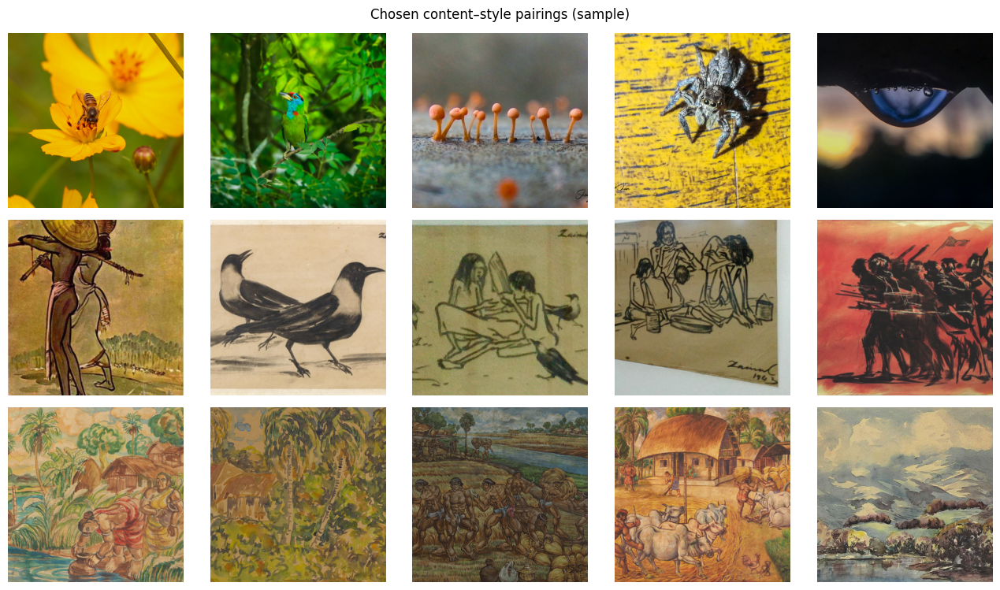

In [3]:
def load_paths(d):
    return sorted([p for p in Path(d).iterdir()
                   if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}])
def load_pil(path, size=None):
    size = size or CFG.img_size
    return ImageOps.fit(Image.open(path).convert("RGB"), (size, size), Image.LANCZOS)

content_paths = load_paths(CFG.content_dir)
content_imgs  = [load_pil(p) for p in content_paths]
ABEDIN_DIR = Path(CFG.style_root)/"jaynul abedin"
SULTAN_DIR = Path(CFG.style_root)/"sm sultan"

# content index -> chosen painting filename per artist (matched by palette / subject / mood)
ABEDIN_PAIR = ["5.png","6.png","2.jpg","1.jpg","3.jpg","7.png","4.png","8.png","6.png","1.jpg"]
SULTAN_PAIR = ["1.Jpeg","2.Jpeg","5.Jpeg","4.Jpeg","10.Jpeg","6.Jpeg","11.Jpeg","8.Jpeg","6.Jpeg","7.Jpeg"]
assert len(content_imgs) == len(ABEDIN_PAIR) == len(SULTAN_PAIR)

def _style(dirp, name): return load_pil(dirp/name)
TASKS = []   # 20 tasks: each content stylised by an Abedin and a Sultan painting
for ci in range(len(content_imgs)):
    TASKS.append(dict(ci=ci, artist="Abedin", style=_style(ABEDIN_DIR, ABEDIN_PAIR[ci]), style_name=ABEDIN_PAIR[ci]))
    TASKS.append(dict(ci=ci, artist="Sultan", style=_style(SULTAN_DIR, SULTAN_PAIR[ci]), style_name=SULTAN_PAIR[ci]))
print(f"{len(content_imgs)} content images x 2 artists = {len(TASKS)} stylization tasks")

def grid_imgs(imgs, titles, suptitle, fname, ncols=5, fs=2.5):
    n=len(imgs); nrows=math.ceil(n/ncols)
    fig,ax=plt.subplots(nrows,ncols,figsize=(fs*ncols,fs*1.15*nrows)); ax=np.array(ax).reshape(-1)
    for a in ax: a.axis("off")
    for a,im,t in zip(ax,imgs,titles): a.imshow(im); a.set_title(t, fontsize=8)
    fig.suptitle(suptitle); fig.tight_layout()
    fig.savefig(FIG/fname, dpi=130, bbox_inches="tight"); plt.show()

grid_imgs(content_imgs, [p.name for p in content_paths], "Content images (10)", "d_content.png")
grid_imgs([load_pil(ABEDIN_DIR/n) for n in sorted({*ABEDIN_PAIR})],
          sorted({*ABEDIN_PAIR}), "Zainul Abedin paintings used", "d_abedin.png")
grid_imgs([load_pil(SULTAN_DIR/n) for n in sorted({*SULTAN_PAIR})],
          sorted({*SULTAN_PAIR}), "S. M. Sultan paintings used", "d_sultan.png")

# preview the chosen pairings (content | Abedin style | Sultan style) for a few
kk=5
fig,axes=plt.subplots(3,kk,figsize=(2.6*kk,7.6))
for j in range(kk):
    axes[0,j].imshow(content_imgs[j]); axes[1,j].imshow(_style(ABEDIN_DIR,ABEDIN_PAIR[j])); axes[2,j].imshow(_style(SULTAN_DIR,SULTAN_PAIR[j]))
    for r in range(3): axes[r,j].axis("off")
for r,t in enumerate(["content","Abedin style","Sultan style"]): axes[r,0].set_ylabel(t, fontsize=10)
fig.suptitle("Chosen content–style pairings (sample)"); fig.tight_layout()
fig.savefig(FIG/"d_pairings.png", dpi=130, bbox_inches="tight"); plt.show()

## 3. Neural Style Transfer (Task 2)

Classical **Gatys et al.** NST on **VGG-19**. Content loss at **conv4\_2**; style loss at
**conv1\_1, conv2\_1, conv3\_1, conv4\_1, conv5\_1** via **Gram matrices**; the generated image is
optimised by **gradient descent**.

- **VGG-19** — ImageNet-pretrained CNN used as a *frozen feature extractor* (shallow layers = texture,
  deep layers = structure).
- **Content loss** — MSE of conv4\_2 features (output vs. content); preserves layout.
- **Style loss** — MSE of **Gram matrices** across five layers; matches texture statistics.
- **Gram matrix** $G=FF^{\top}$ — channel correlations that encode style (brush texture, colour
  co-occurrence) independent of position.
- **Image optimisation** — the output pixels are the variables; starting from the content image we
  minimise $w_cL_{content}+w_sL_{style}$, so each pair needs its own optimisation loop.

In [4]:
vgg = vgg19(weights=VGG19_Weights.DEFAULT).features.eval().to(device)
for p in vgg.parameters(): p.requires_grad_(False)
CONTENT_LAYERS = {21: "conv4_2"}
STYLE_LAYERS   = {0: "conv1_1", 5: "conv2_1", 10: "conv3_1", 19: "conv4_1", 28: "conv5_1"}
_mean = torch.tensor([0.485,0.456,0.406], device=device).view(1,3,1,1)
_std  = torch.tensor([0.229,0.224,0.225], device=device).view(1,3,1,1)
def _norm(x): return (x - _mean)/_std
def vgg_features(x, layers):
    x=_norm(x); feats={}
    for i,layer in enumerate(vgg):
        x=layer(x)
        if i in layers: feats[layers[i]]=x
        if i>=max(layers): break
    return feats
def gram(f):
    b,c,h,w=f.shape; F_=f.view(c,h*w); return (F_@F_.t())/(c*h*w)
def pil_to_tensor(pil): return transforms.functional.to_tensor(pil).unsqueeze(0).to(device)
def tensor_to_pil(t):   return transforms.functional.to_pil_image(t.detach().cpu().clamp(0,1).squeeze(0))

def run_nst(content_pil, style_pil, steps=None, seed=0):
    steps=steps or CFG.nst_steps; set_seed(seed)
    content=pil_to_tensor(content_pil); style=pil_to_tensor(style_pil)
    c_t={k:v.detach() for k,v in vgg_features(content,CONTENT_LAYERS).items()}
    s_t={k:gram(v).detach() for k,v in vgg_features(style,STYLE_LAYERS).items()}
    img=content.clone().requires_grad_(True); opt=torch.optim.Adam([img], lr=CFG.nst_lr)
    for _ in range(steps):
        opt.zero_grad()
        cf=vgg_features(img,CONTENT_LAYERS); sf=vgg_features(img,STYLE_LAYERS)
        c_loss=sum(F.mse_loss(cf[k],c_t[k]) for k in c_t)
        s_loss=sum(F.mse_loss(gram(sf[k]),s_t[k]) for k in s_t)/len(s_t)
        loss=CFG.nst_content_weight*c_loss + CFG.nst_style_weight*s_loss
        loss.backward(); opt.step()
        with torch.no_grad(): img.clamp_(0,1)
    return tensor_to_pil(img)

In [5]:
nst_outputs, nst_times = [], []
for tk in tqdm(TASKS, desc="NST"):
    t0=time.time(); out=run_nst(content_imgs[tk["ci"]], tk["style"], seed=CFG.seed)
    if use_cuda: torch.cuda.synchronize()
    nst_times.append(time.time()-t0)
    out.save(DIRS["nst"]/f"nst_{tk['artist']}_{tk['ci']:02d}.png"); nst_outputs.append(out)
print(f"NST mean time/image: {np.mean(nst_times):.1f}s   ({len(TASKS)} images)")

NST:   0%|          | 0/20 [00:00<?, ?it/s]

NST mean time/image: 4.3s   (20 images)


## 4. Adaptive Instance Normalization — AdaIN (Task 3)

A fixed VGG **encoder** maps content/style to features; **AdaIN** replaces the channel-wise mean/std
of the content features with the style's; a trained **decoder** inverts them to an image — all in one
feed-forward pass.

$$\mathrm{AdaIN}(x,y)=\sigma(y)\frac{x-\mu(x)}{\sigma(x)}+\mu(y)$$

- **Encoder** (VGG up to relu4\_1, frozen) — the feature space.
- **AdaIN op** — aligns per-channel mean/std (a channel's mean/variance summarise its texture), so
  style is applied with no optimisation.
- **Decoder** — trained (COCO content + WikiArt style) to invert stylised features to pixels.
- **Content loss** — MSE to the AdaIN target `t`; **Style loss** — matches mean/std across VGG layers
  (used to train the decoder; here we only run inference).

We load the standard pretrained `vgg_normalised` + `decoder` weights from the Hugging Face Hub.

In [6]:
from huggingface_hub import hf_hub_download
adain_decoder = nn.Sequential(
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(512,256,3), nn.ReLU(),
    nn.Upsample(scale_factor=2, mode='nearest'),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(256,256,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(256,256,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(256,256,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(256,128,3), nn.ReLU(),
    nn.Upsample(scale_factor=2, mode='nearest'),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(128,128,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(128,64,3), nn.ReLU(),
    nn.Upsample(scale_factor=2, mode='nearest'),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(64,64,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(64,3,3),
)
adain_vgg = nn.Sequential(
    nn.Conv2d(3,3,1),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(3,64,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(64,64,3), nn.ReLU(),
    nn.MaxPool2d(2,2,ceil_mode=True),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(64,128,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(128,128,3), nn.ReLU(),
    nn.MaxPool2d(2,2,ceil_mode=True),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(128,256,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(256,256,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(256,256,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(256,256,3), nn.ReLU(),
    nn.MaxPool2d(2,2,ceil_mode=True),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(256,512,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(512,512,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(512,512,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(512,512,3), nn.ReLU(),
    nn.MaxPool2d(2,2,ceil_mode=True),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(512,512,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(512,512,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(512,512,3), nn.ReLU(),
    nn.ReflectionPad2d((1,1,1,1)), nn.Conv2d(512,512,3), nn.ReLU(),
)
REPO="BhupatiNadar/adain-style-transfer-models"
def _strip(sd):
    sd=sd.get("state_dict",sd) if isinstance(sd,dict) else sd
    return {(k[4:] if k.startswith("net.") else k):v for k,v in sd.items()}
adain_vgg.load_state_dict(_strip(torch.load(hf_hub_download(REPO,"vgg_normalized.pth"), map_location="cpu")))
adain_decoder.load_state_dict(_strip(torch.load(hf_hub_download(REPO,"decoder_final.pth"), map_location="cpu")))
adain_enc = nn.Sequential(*list(adain_vgg.children())[:31]).eval().to(device)
adain_decoder = adain_decoder.eval().to(device)
for p in adain_enc.parameters(): p.requires_grad_(False)
for p in adain_decoder.parameters(): p.requires_grad_(False)
print("AdaIN encoder + decoder loaded")

def _mean_std(f, eps=1e-5):
    b,c=f.shape[:2]
    std=(f.view(b,c,-1).var(dim=2)+eps).sqrt().view(b,c,1,1)
    mean=f.view(b,c,-1).mean(dim=2).view(b,c,1,1)
    return mean,std
def adain(cf,sf):
    cm,cs=_mean_std(cf); sm,ss=_mean_std(sf); return ss*(cf-cm)/cs+sm
@torch.no_grad()
def run_adain(content_pil, style_pil, alpha=1.0):
    c=pil_to_tensor(content_pil); s=pil_to_tensor(style_pil)
    cf=adain_enc(c); sf=adain_enc(s); t=adain(cf,sf); t=alpha*t+(1-alpha)*cf
    return tensor_to_pil(adain_decoder(t))

AdaIN encoder + decoder loaded


In [7]:
adain_outputs, adain_times = [], []
for tk in tqdm(TASKS, desc="AdaIN"):
    t0=time.time(); out=run_adain(content_imgs[tk["ci"]], tk["style"], alpha=1.0)
    if use_cuda: torch.cuda.synchronize()
    adain_times.append(time.time()-t0)
    out.save(DIRS["adain"]/f"adain_{tk['artist']}_{tk['ci']:02d}.png"); adain_outputs.append(out)
print(f"AdaIN mean time/image: {np.mean(adain_times)*1000:.1f} ms")

AdaIN:   0%|          | 0/20 [00:00<?, ?it/s]

AdaIN mean time/image: 25.7 ms


## 5. Stable Diffusion–based style transfer (Task 4)

To change **only the style, not the object**, we combine three controls on **SD-1.5** so the content
structure is held fixed while the appearance is repainted in the artist's style:

- **img2img** — the content photo initialises the latent (keeps rough colours/layout);
- **ControlNet (Canny)** — locks the output to the **content's edges**, so the object/structure is
  preserved (this is what stops SD from turning the flower into a village);
- **IP-Adapter** — injects the **painting's style**, kept at a *modest* scale so the painting's own
  *subjects* are not copied in — only its brushwork/palette — plus a short artist text prompt.

- **VAE** — content image ↔ 64×64×4 latent (diffusion runs in latent space).
- **Denoising UNet** — repaints the latent; ControlNet adds edge guidance at every step.
- **Conditioning** — text prompt (CLIP) + style painting (IP-Adapter) + **content edges (ControlNet)**
  + noised content latent (img2img); together they fix the object and vary only the style.
- **Diffusion process** — reverse denoising; **strength / guidance / steps** trade style intensity vs.
  speed, while **ControlNet keeps the object fixed**.

In [8]:
import cv2
from diffusers import ControlNetModel, StableDiffusionControlNetImg2ImgPipeline, DPMSolverMultistepScheduler

def canny_image(pil, low=80, high=180):
    e = cv2.Canny(np.array(pil.convert("RGB")), low, high)
    return Image.fromarray(np.stack([e, e, e], axis=-1))

controlnet = ControlNetModel.from_pretrained("lllyasviel/sd-controlnet-canny", torch_dtype=weight_dtype)
sd = StableDiffusionControlNetImg2ImgPipeline.from_pretrained(
    CFG.sd_model_id, controlnet=controlnet, torch_dtype=weight_dtype,
    safety_checker=None, requires_safety_checker=False)
sd.scheduler = DPMSolverMultistepScheduler.from_config(sd.scheduler.config)
sd.set_progress_bar_config(disable=True); sd = sd.to(device)

USE_IP = CFG.use_ip_adapter
if USE_IP:
    try:
        sd.load_ip_adapter("h94/IP-Adapter", subfolder="models", weight_name="ip-adapter_sd15.bin")
        sd.set_ip_adapter_scale(CFG.sd_ip_scale)
        print("Loaded: ControlNet-Canny (structure) + IP-Adapter (style)")
    except Exception as e:
        print("[warn] IP-Adapter unavailable -> text-prompt style only:", str(e)[:100]); USE_IP=False

ARTIST_PROMPT = {
 "Abedin": "in the style of Zainul Abedin, expressive brush and ink painting, hand-drawn strokes",
 "Sultan": "in the style of S. M. Sultan, vibrant rural Bengal oil painting, earthy colours, bold brushwork",
}
NEG_PROMPT = "low quality, blurry, jpeg artifacts, watermark, text, frame, extra objects, deformed"

def run_sd(content_pil, style_pil, artist="Abedin", strength=None, guidance=None, steps=None, seed=0):
    g=torch.Generator(device=device).manual_seed(seed)
    kw=dict(prompt=ARTIST_PROMPT.get(artist,"a fine-art painting"), negative_prompt=NEG_PROMPT,
            image=content_pil, control_image=canny_image(content_pil),
            strength=strength if strength is not None else CFG.sd_strength,
            guidance_scale=guidance if guidance is not None else CFG.sd_guidance,
            num_inference_steps=steps or CFG.sd_steps,
            controlnet_conditioning_scale=CFG.sd_controlnet_scale, generator=g)
    if USE_IP: kw["ip_adapter_image"]=style_pil
    return sd(**kw).images[0]

# show that Canny preserves structure, then smoke-test
_c = canny_image(content_imgs[0])
try:
    _=run_sd(content_imgs[0], TASKS[0]["style"], "Abedin", steps=8); print("SD OK (IP-Adapter=",USE_IP,")")
except Exception as e:
    print("[warn] disabling IP-Adapter after inference error:", str(e)[:100]); USE_IP=False
    try: sd.unload_ip_adapter()
    except Exception: pass
    _=run_sd(content_imgs[0], TASKS[0]["style"], "Abedin", steps=8); print("SD OK (text fallback)")

config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


diffusion_pytorch_model.safetensors:   0%|          | 0.00/1.45G [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loaded: ControlNet-Canny (structure) + IP-Adapter (style)


SD OK (IP-Adapter= True )


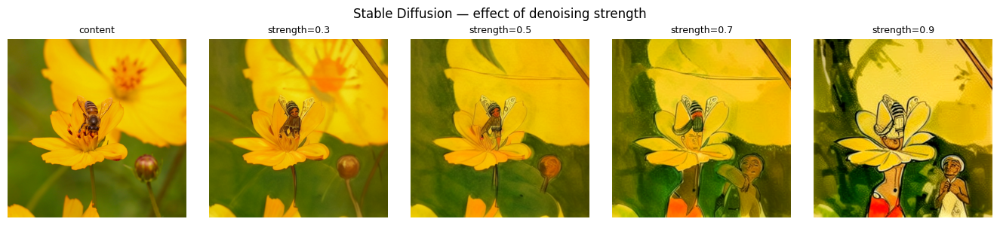

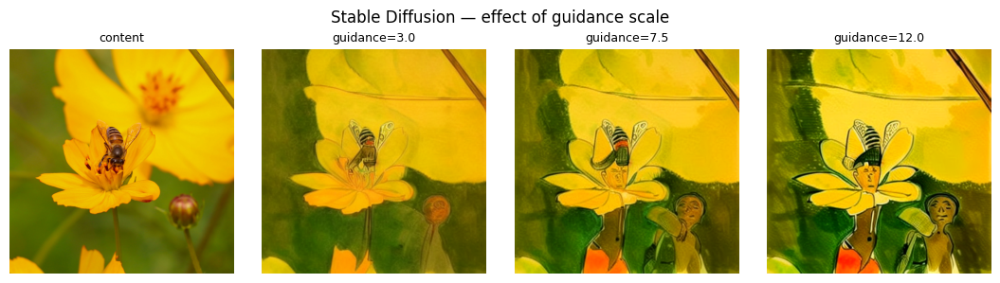

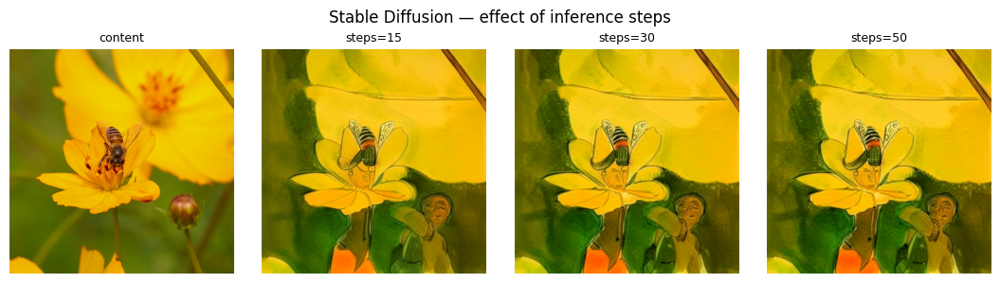

In [9]:
# parameter study on one showcase pair (content 0 + its Abedin painting)
c0, s0 = content_imgs[0], TASKS[0]["style"]
def sweep(param, values):
    imgs=[c0]; labels=["content"]
    for v in values:
        kw=dict(strength=CFG.sd_strength, guidance=CFG.sd_guidance, steps=CFG.sd_steps, seed=CFG.seed)
        kw[param]=v; imgs.append(run_sd(c0,s0,"Abedin",**kw)); labels.append(f"{param}={v}")
    return imgs, labels
for name,param,vals in [("denoising strength","strength",[0.3,0.5,0.7,0.9]),
                        ("guidance scale","guidance",[3.0,7.5,12.0]),
                        ("inference steps","steps",[15,30,50])]:
    imgs,labels=sweep(param,vals); n=len(imgs)
    fig,ax=plt.subplots(1,n,figsize=(2.7*n,3.0))
    for a,im,t in zip(ax,imgs,labels): a.imshow(im); a.axis("off"); a.set_title(t, fontsize=9)
    fig.suptitle(f"Stable Diffusion — effect of {name}"); fig.tight_layout()
    fig.savefig(FIG/f"sd_sweep_{param}.png", dpi=130, bbox_inches="tight"); plt.show()

In [10]:
sd_outputs, sd_times = [], []
for tk in tqdm(TASKS, desc="SD"):
    t0=time.time(); out=run_sd(content_imgs[tk["ci"]], tk["style"], tk["artist"], seed=CFG.seed)
    if use_cuda: torch.cuda.synchronize()
    sd_times.append(time.time()-t0)
    out.save(DIRS["sd"]/f"sd_{tk['artist']}_{tk['ci']:02d}.png"); sd_outputs.append(out)
print(f"SD mean time/image: {np.mean(sd_times):.1f}s")

SD:   0%|          | 0/20 [00:00<?, ?it/s]

SD mean time/image: 1.5s


## 6. Comparative evaluation (Task 5)

For every (content, painting) pair we compare the three outputs on:

- **Content preservation** — SSIM and LPIPS to the content photo (higher SSIM / lower LPIPS = more
  structure kept).
- **Style similarity** — VGG **Gram-matrix distance** to the painting (lower = closer style) and
  **CLIP image similarity** to the painting (higher = more like it).
- **Processing time**; **computational needs / controllability** are summarised qualitatively.

Metrics are averaged over all 20 stylizations and broken down by artist.

In [11]:
from torchmetrics.functional import structural_similarity_index_measure as ssim_fn
try:
    from torchmetrics.image.lpip import LearnedPerceptualImagePatchSimilarity
    _lpips=LearnedPerceptualImagePatchSimilarity(net_type="vgg", normalize=True).to(device)
    def lpips_dist(a,b): return float(_lpips(pil_to_tensor(a), pil_to_tensor(b)).detach().cpu())
except Exception as e:
    print("[warn] LPIPS unavailable:", str(e)[:80]); lpips_dist=lambda a,b: float("nan")
from transformers import CLIPModel, CLIPProcessor
clip_model=CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
clip_proc =CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
@torch.no_grad()
def clip_img_sim(a,b):
    inp=clip_proc(images=[np.array(a),np.array(b)], return_tensors="pt").to(device)
    f=clip_model.get_image_features(**inp); f=f/f.norm(dim=-1,keepdim=True); return float((f[0]@f[1]).cpu())
@torch.no_grad()
def gram_style_dist(o_pil,s_pil):
    of=vgg_features(pil_to_tensor(o_pil),STYLE_LAYERS); sf=vgg_features(pil_to_tensor(s_pil),STYLE_LAYERS)
    return float(sum(F.mse_loss(gram(of[k]),gram(sf[k])) for k in of).cpu())
def ssim_content(o_pil,c_pil): return float(ssim_fn(pil_to_tensor(o_pil),pil_to_tensor(c_pil)).cpu())

methods={"NST":nst_outputs,"AdaIN":adain_outputs,"SD":sd_outputs}
times  ={"NST":nst_times,"AdaIN":adain_times,"SD":sd_times}
per_rows=[]
for m,outs in methods.items():
    for tk,out,tm in zip(TASKS,outs,times[m]):
        per_rows.append({"method":m,"artist":tk["artist"],"content":tk["ci"],
            "SSIM":ssim_content(out,content_imgs[tk["ci"]]),
            "LPIPS":lpips_dist(out,content_imgs[tk["ci"]]),
            "Gram":gram_style_dist(out,tk["style"]),
            "CLIPstyle":clip_img_sim(out,tk["style"]),"time":tm})
per_df=pd.DataFrame(per_rows); per_df.to_csv(RES/"per_image_metrics.csv", index=False)

def summarise(df):
    return pd.DataFrame([{
        "Method":m,
        "Content SSIM ↑":round(g["SSIM"].mean(),3),
        "Content LPIPS ↓":round(g["LPIPS"].mean(),3),
        "Style Gram-dist ↓":round(g["Gram"].mean(),4),
        "CLIP style-sim ↑":round(g["CLIPstyle"].mean(),3),
        "Time/img (s)":round(g["time"].mean(),2),
    } for m,g in df.groupby("method")])
comp_df=summarise(per_df); comp_df.to_csv(RES/"comparison_metrics.csv", index=False)
print("=== overall (mean over 20 stylizations) ==="); print(comp_df.to_string(index=False))
print("\n=== CLIP style-sim by method x artist ===")
print(per_df.pivot_table(index="method", columns="artist", values="CLIPstyle", aggfunc="mean").round(3))

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


=== overall (mean over 20 stylizations) ===
Method  Content SSIM ↑  Content LPIPS ↓  Style Gram-dist ↓  CLIP style-sim ↑  Time/img (s)
 AdaIN           0.321            0.662             0.0002             0.609          0.03
   NST           0.380            0.461             0.0000             0.553          4.27
    SD           0.514            0.556             0.0006             0.719          1.50

=== CLIP style-sim by method x artist ===
artist  Abedin  Sultan
method                
AdaIN    0.607   0.611
NST      0.551   0.555
SD       0.709   0.729


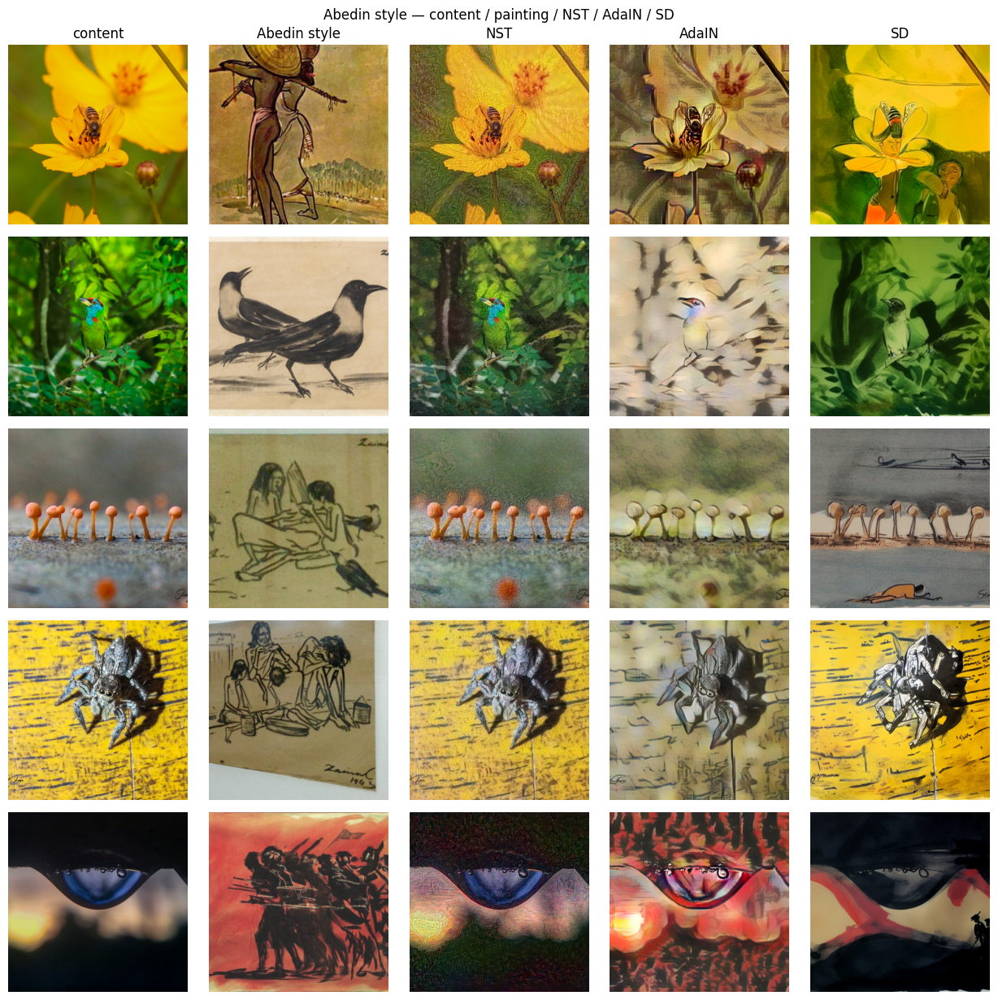

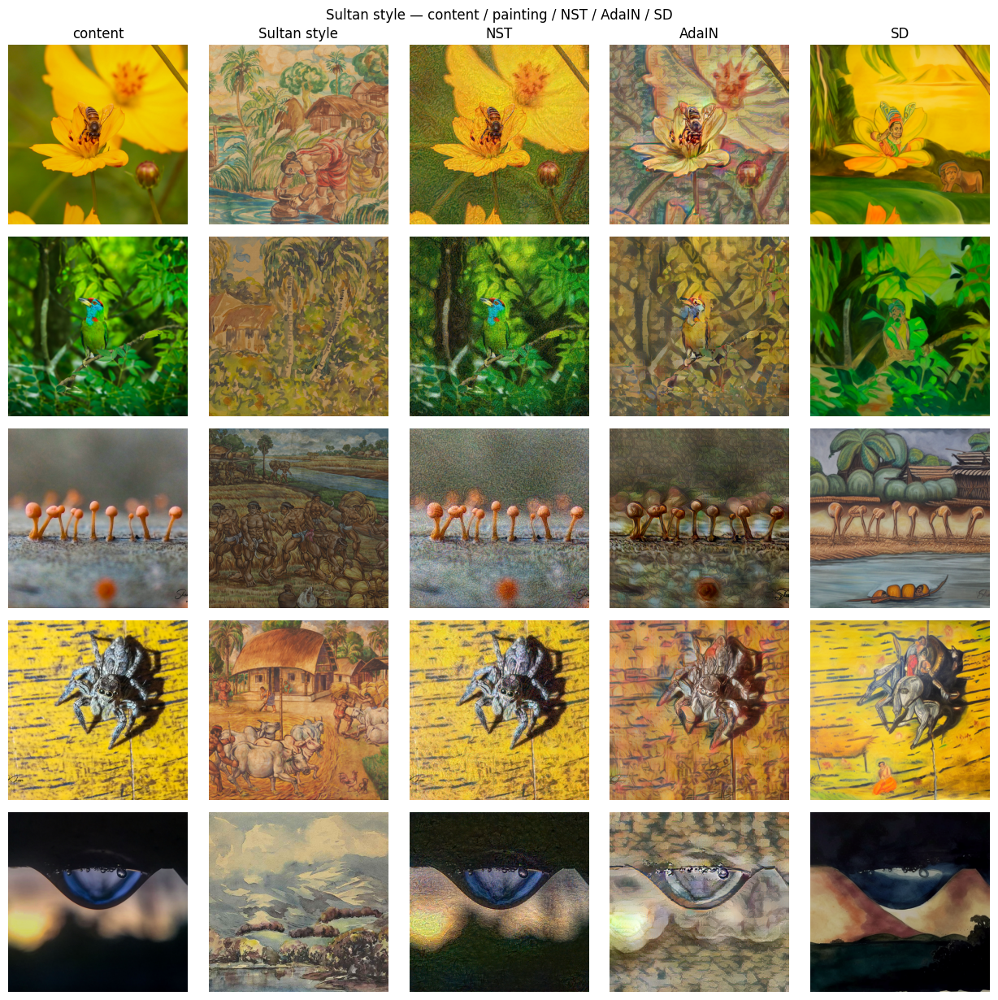

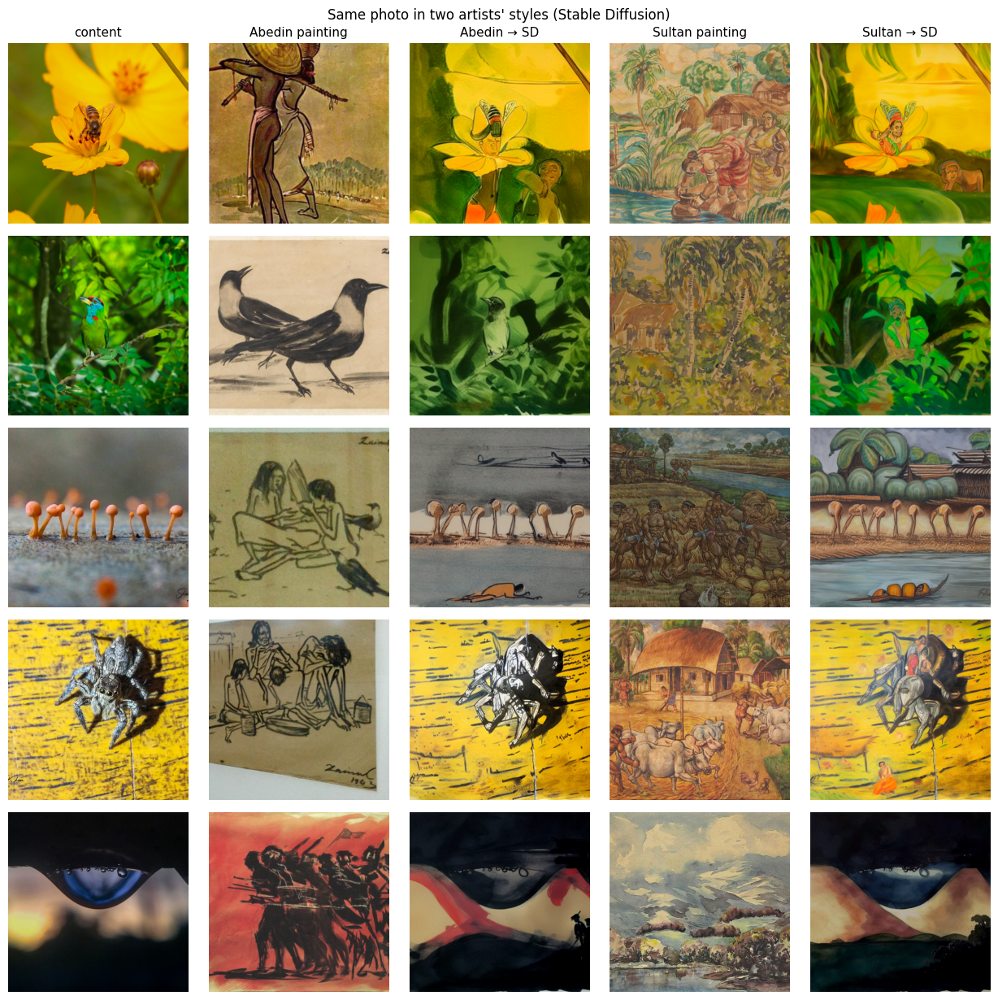

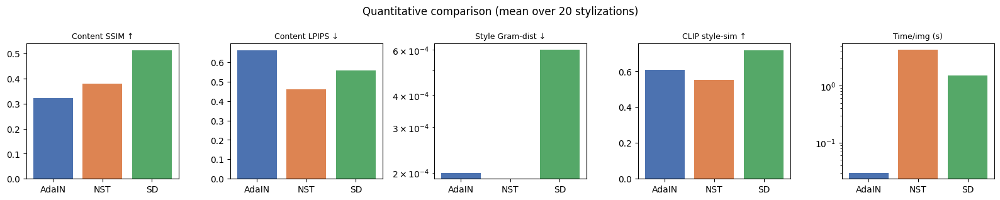

In [12]:
# per-artist comparison grids: rows=content, cols = content / painting / NST / AdaIN / SD
def artist_grid(artist, fname, n=5):
    idx=[k for k,tk in enumerate(TASKS) if tk["artist"]==artist][:n]
    fig,axes=plt.subplots(len(idx),5,figsize=(5*2.5,len(idx)*2.5)); axes=np.array(axes).reshape(len(idx),5)
    cols=["content",f"{artist} style","NST","AdaIN","SD"]
    for r,k in enumerate(idx):
        tk=TASKS[k]
        ims=[content_imgs[tk["ci"]], tk["style"], nst_outputs[k], adain_outputs[k], sd_outputs[k]]
        for c,im in enumerate(ims):
            axes[r,c].imshow(im); axes[r,c].axis("off")
            if r==0: axes[r,c].set_title(cols[c], fontsize=12)
    fig.suptitle(f"{artist} style — content / painting / NST / AdaIN / SD"); fig.tight_layout()
    fig.savefig(FIG/fname, dpi=130, bbox_inches="tight"); plt.show()
artist_grid("Abedin","comparison_abedin.png")
artist_grid("Sultan","comparison_sultan.png")

# same photo, both artists (SD outputs): content | Abedin painting | Abedin-SD | Sultan painting | Sultan-SD
kk=5
fig,axes=plt.subplots(kk,5,figsize=(5*2.5,kk*2.5))
for r in range(kk):
    a=2*r; s=2*r+1   # task indices: even=Abedin, odd=Sultan for content r
    row=[content_imgs[r], TASKS[a]["style"], sd_outputs[a], TASKS[s]["style"], sd_outputs[s]]
    for c,im in enumerate(row): axes[r,c].imshow(im); axes[r,c].axis("off")
for c,t in enumerate(["content","Abedin painting","Abedin → SD","Sultan painting","Sultan → SD"]):
    axes[0,c].set_title(t, fontsize=11)
fig.suptitle("Same photo in two artists' styles (Stable Diffusion)"); fig.tight_layout()
fig.savefig(FIG/"two_artist_showcase.png", dpi=130, bbox_inches="tight"); plt.show()

# metric bar charts
mp=["Content SSIM ↑","Content LPIPS ↓","Style Gram-dist ↓","CLIP style-sim ↑","Time/img (s)"]
fig,ax=plt.subplots(1,len(mp),figsize=(3.2*len(mp),3.2)); colors=["#4c72b0","#dd8452","#55a868"]
for a,mname in zip(ax,mp):
    a.bar(comp_df["Method"],comp_df[mname],color=colors); a.set_title(mname,fontsize=9)
    if "Time" in mname or "Gram" in mname: a.set_yscale("log")
fig.suptitle("Quantitative comparison (mean over 20 stylizations)"); fig.tight_layout()
fig.savefig(FIG/"comparison_metrics.png", dpi=130, bbox_inches="tight"); plt.show()

## 7. Discussion (Task 6)

### Evolution: NST → AdaIN → Stable Diffusion
- **NST (2015)** — style = **Gram-matrix feature correlations**; transfer = per-image *optimisation*.
- **AdaIN (2017)** — style = **feature statistics (mean/std)**; transfer = one *feed-forward* pass.
- **Stable Diffusion (2022)** — style = a learned **generative prior** conditioned on text/image;
  transfer = *iterative denoising* in latent space, able to invent coherent new detail.

The mechanism moves from hand-designed statistics (Gram → mean/std) to a learned generative model,
and from optimising one image to sampling from a conditioned distribution. The two artists stress
this differently: Abedin's sparse **ink-brush/sepia sketch** style is mostly texture+palette
(handled well even by NST/AdaIN), whereas Sultan's **dense, colourful oil** style with figures is
better captured by SD's generative prior.

### Answers
1. **Best content preservation** — NST/AdaIN stay anchored to the content features; check the
   Content-SSIM / LPIPS columns (NST usually lowest LPIPS).
2. **Most effective style transfer** — **Stable Diffusion** (highest CLIP-style-sim to the paintings),
   especially for Sultan's rich oil style; NST matches literal texture/colour best (lowest Gram-dist).
3. **Highest visual quality** — **Stable Diffusion** (coherent, painterly, artefact-free).
4. **Fastest** — **AdaIN** (a single forward pass, milliseconds).
5. **Most computational resources** — **Stable Diffusion** (~1 B-param UNet + VAE + encoders).
6. **Greatest control** — **Stable Diffusion** (prompt, strength, guidance, steps, IP-Adapter scale,
   seed); NST offers content/style weights; AdaIN only the `alpha` blend.
7. **Why SD can modify content structure** — it regenerates the image by denoising a latent, so it is
   not tied to the content pixels and can add/remove/reshape content at higher strength.
8. **Why NST needs per-pair optimisation** — it trains no transfer network; the output pixels are the
   variables, optimised from scratch against the VGG losses for every content–style pair.
9. **Why AdaIN is faster than NST** — it replaces the optimisation loop with one feed-forward pass and
   a closed-form mean/std alignment instead of hundreds of gradient steps.
10. **Recommendation** — for faithfully applying Abedin's or Sultan's painterly style to new photos
    with the best quality and control, **Stable Diffusion (img2img + IP-Adapter)**; for real-time use
    **AdaIN**, and for the most literal texture match **NST**.

All 60 generated images and the figures/metrics are saved under `outputs/`.